# Geometric Camera Calibration Across Working Distances
## Working Distance Characterization (0.2m, 0.3m, 0.4m, 0.5m, 0.6m)

This notebook evaluates the geometric camera calibration parameters across multiple working distances:
- **0.2m, 0.3m, 0.4m, 0.5m, 0.6m** under `images/checkerboard/`

### Objectives:
1. Perform Zhang's extended camera calibration for each distance individually and for all distances combined.
2. Generate a **Calibration Working Distance Summary Table** comparing focal lengths, principal points, radial distortion, and RMS reprojection errors.
3. Display individual 2-panel diagnostic residual plots for each working distance folder.
4. Generate a **Unified Multi-Distance Residual Plot** assigning consistent, unique colors to each working distance.

In [1]:
# =========================================================================
# ENVIRONMENT SETUP & CONFIGURATION LOADING
# =========================================================================
%matplotlib inline
import os
import sys
import yaml
import glob
import numpy as np
import rawpy
import colour
import matplotlib.pyplot as plt
from pathlib import Path
import cv2
import tifffile
import pandas as pd

np.set_printoptions(precision=4, suppress=True)
# -----------------------------------------------------------------------------
# SET YOUR REPOSITORY PATH HERE:
# Point to your project root
# -----------------------------------------------------------------------------
REPO_ROOT = r"C:\Users\nmmon\Desktop\EE513\Project1\camera_characterization"

repo_path_obj = Path(REPO_ROOT).resolve()
src_path_obj = repo_path_obj / "src"

for p in [str(repo_path_obj), str(src_path_obj)]:
    if os.path.exists(p) and p not in sys.path:
        sys.path.insert(0, p)

#import camera_toolkit modules
try:
    from camera_toolkit import utils, geometry, resolution, noise, color, plots, simulator
    print(f"Successfully imported camera_toolkit from: {src_path_obj if src_path_obj.exists() else repo_path_obj}")
except ModuleNotFoundError:
    sys.path.insert(0, str(Path(".").resolve() / "src"))
    sys.path.insert(0, str(Path(".").resolve()))
    from camera_toolkit import utils, geometry, resolution, noise, color, plots, simulator
    print("Successfully imported camera_toolkit using relative fallback.")

#load configuration from config.yaml
config_path = os.path.join(REPO_ROOT, "config.yaml") if os.path.exists(os.path.join(REPO_ROOT, "config.yaml")) else "config.txt"
if os.path.exists(config_path):
    with open(config_path, "r") as f:
        config = yaml.safe_load(f)
else:
    config = {
        "project": {"camera_name": "Google Pixel 9", "output_dir": os.path.join(REPO_ROOT, "outputs")},
        "geometry": {
            "input_dir": os.path.join(REPO_ROOT, "images", "checkerboard", "all"),
            "file_extension": ".dng",
            "checkerboard": {"rows": 6, "cols": 9, "square_size_mm": 19.0}
        },
        "resolution": {"input_dir": os.path.join(REPO_ROOT, "images", "resolution"), "file_extension": ".dng"},
        "noise": {"flat_dir": os.path.join(REPO_ROOT, "images", "flat_fields"), "dark_dir": os.path.join(REPO_ROOT, "images", "dark_frames"), "file_extension": ".dng"},
        "color": {"input_dir": os.path.join(REPO_ROOT, "images", "color"), "file_extension": ".dng"}
    }

output_dir = config["project"].get("output_dir", "./outputs")
os.makedirs(output_dir, exist_ok=True)
print(f"Successfully initialized configuration. Output directory: {output_dir}")

# -----------------------------------------------------------------------------
# Environment verification
# -----------------------------------------------------------------------------
utils.verify_environment()



Successfully imported camera_toolkit from: C:\Users\nmmon\Desktop\EE513\Project1\camera_characterization\src
Successfully initialized configuration. Output directory: ./outputs
--- Environment Validation ---
Python     : 3.12.15
rawpy      : 0.27.1
colour     : 0.4.7
numpy      : 2.5.3
cv2        : 5.0.0
yaml       : 6.0.3
matplotlib : 3.11.2
tifffile   : 2026.9.20
Environment Validation Passed Successfully.



True

In [2]:
# Calibration Constants
CHECKERBOARD_ROWS = 6
CHECKERBOARD_COLS = 9
SQUARE_SIZE_MM = 19.0

# Consistent Color Mapping & Human-Readable Labels for Working Distances
DISTANCE_COLORS = {
    "0_2m": "#E63946",  # Coral Red
    "0_3m": "#F4A261",  # Amber Orange
    "0_4m": "#2A9D8F",  # Teal Green
    "0_5m": "#457B9D",  # Steel Blue
    "0_6m": "#1D3557"   # Deep Navy
}

DISTANCE_LABELS = {
    "0_2m": "0.2m Working Distance",
    "0_3m": "0.3m Working Distance",
    "0_4m": "0.4m Working Distance",
    "0_5m": "0.5m Working Distance",
    "0_6m": "0.6m Working Distance"
}

In [ ]:
def detect_and_calibrate_folder(folder_path, rows=CHECKERBOARD_ROWS, cols=CHECKERBOARD_COLS, square_size_mm=SQUARE_SIZE_MM):
    """
    Loads all checkerboard images from a folder, detects corners, and runs extended calibration.
    """
    # FIX: Use toolkit utility to find strictly .dng files
    image_paths = utils.find_target_images(folder_path, extension=".dng")
    
    if not image_paths:
        print(f"No images found in: {folder_path}")
        return None

    all_obj_points = []
    all_img_points = []
    valid_paths = []
    img_shape = None

    obj_p = geometry.generate_object_points(rows, cols, square_size_mm)

    for path in image_paths:
        if path.lower().endswith('.dng'):
            try:
                import rawpy
                with rawpy.imread(path) as raw:
                    img = raw.postprocess(use_camera_wb=True, half_size=False)
            except Exception as e:
                print(f"Error loading raw DNG {path}: {e}")
                continue
        else:
            img = cv2.imread(path)
            
        if img is None:
            continue
            
        if img_shape is None:
            img_shape = (img.shape[1], img.shape[0])  # (width, height)

        success, corners = geometry.detect_checkerboard_corners(img, rows, cols)
        if success:
            all_obj_points.append(obj_p)
            all_img_points.append(corners)
            valid_paths.append(path)

    if not all_img_points:
        print(f"No valid checkerboard corners detected in: {folder_path}")
        return None

    # Run extended calibration
    calib_payload = geometry.run_extended_calibration(all_obj_points, all_img_points, img_shape)
    calib_payload["all_obj_points"] = all_obj_points
    calib_payload["all_img_points"] = all_img_points
    calib_payload["valid_paths"] = valid_paths
    calib_payload["total_images"] = len(image_paths)
    calib_payload["detected_images"] = len(valid_paths)
    calib_payload["img_shape"] = img_shape
    
    return calib_payload

RUNNING PER-WORKING-DISTANCE CALIBRATION & DIAGNOSTICS

Processing Working Distance Folder: 0_2m (images\checkerboard\0_2m)...
residual mean [-0.0000 0.0000] px, sd [1.1689 1.3067] px
[PLOT] Saved at: c:\Users\nmmon\Desktop\EE513\Project1\camera_characterization\images\outputs\figures\calibration_residuals_2panel.png


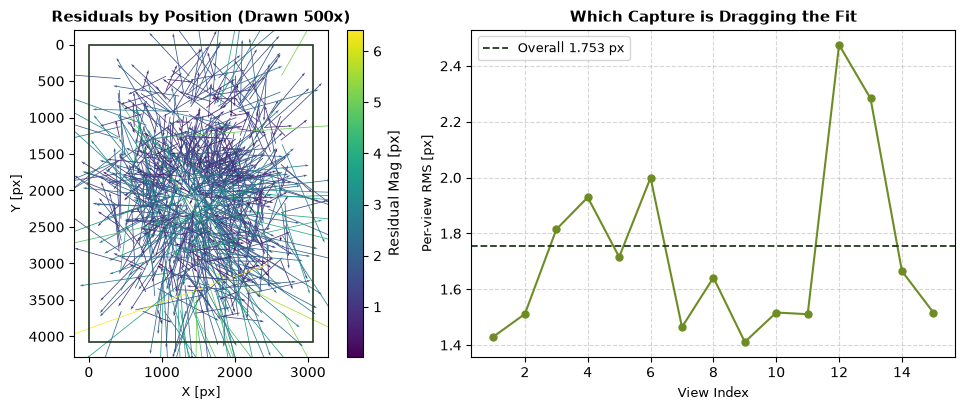


Processing Working Distance Folder: 0_3m (images\checkerboard\0_3m)...
residual mean [0.0000 0.0001] px, sd [0.8110 0.8337] px
[PLOT] Saved at: c:\Users\nmmon\Desktop\EE513\Project1\camera_characterization\images\outputs\figures\calibration_residuals_2panel.png


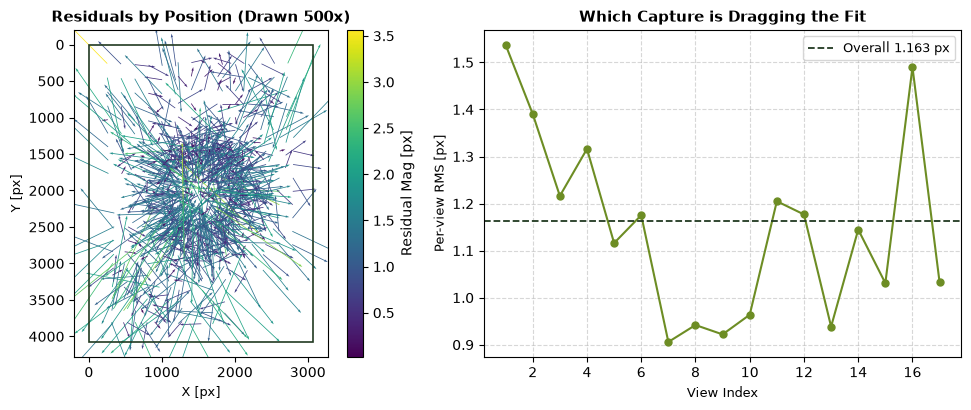


Processing Working Distance Folder: 0_4m (images\checkerboard\0_4m)...
residual mean [0.0000 0.0000] px, sd [0.7156 0.7713] px
[PLOT] Saved at: c:\Users\nmmon\Desktop\EE513\Project1\camera_characterization\images\outputs\figures\calibration_residuals_2panel.png


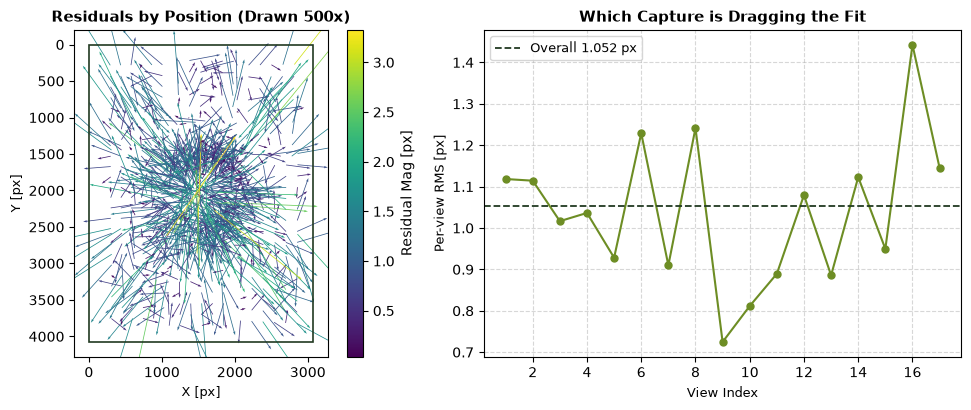


Processing Working Distance Folder: 0_5m (images\checkerboard\0_5m)...
residual mean [0.0000 0.0001] px, sd [0.6173 0.6171] px
[PLOT] Saved at: c:\Users\nmmon\Desktop\EE513\Project1\camera_characterization\images\outputs\figures\calibration_residuals_2panel.png


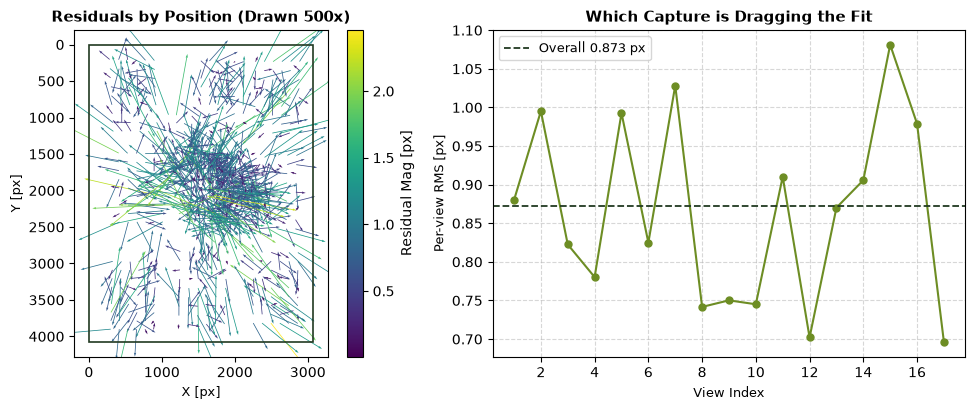


Processing Working Distance Folder: 0_6m (images\checkerboard\0_6m)...
residual mean [0.0000 0.0000] px, sd [0.4325 0.4977] px
[PLOT] Saved at: c:\Users\nmmon\Desktop\EE513\Project1\camera_characterization\images\outputs\figures\calibration_residuals_2panel.png


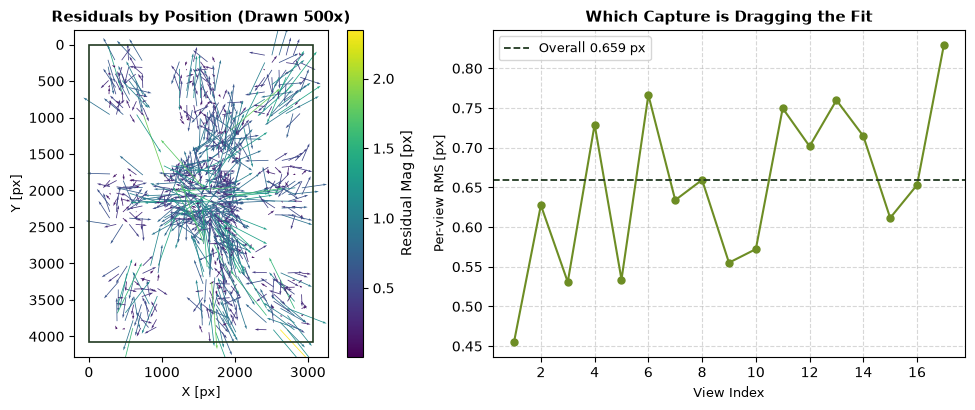

In [4]:
# 1. Iterate over each working distance folder and run individual calibration & diagnostic plots
base_dir = os.path.join("images", "checkerboard")
working_distances = ["0_2m", "0_3m", "0_4m", "0_5m", "0_6m"]

distance_results = {}
all_obj_combined = []
all_img_combined = []
img_shape_global = None

print("=" * 70)
print("RUNNING PER-WORKING-DISTANCE CALIBRATION & DIAGNOSTICS")
print("=" * 70)

for d_key in working_distances:
    folder_path = os.path.join(base_dir, d_key)
    print(f"\nProcessing Working Distance Folder: {d_key} ({folder_path})...")
    
    payload = detect_and_calibrate_folder(folder_path)
    if payload is None:
        continue
        
    distance_results[d_key] = payload
    if img_shape_global is None:
        img_shape_global = payload["img_shape"]

    # Accumulate data for overall combined calibration model
    all_obj_combined.extend(payload["all_obj_points"])
    all_img_combined.extend(payload["all_img_points"])

    # Extract camera matrix and distortion vector
    K_mat = utils.reconstruct_k_matrix(payload)
    dist_vec = utils.reconstruct_dist_vector(payload)

    # CALL PLOTTING FUNCTION (It displays automatically)
    plots.plot_calibration_residuals_2panel(
        all_object_points=payload["all_obj_points"],
        all_image_points=payload["all_img_points"],
        rvecs=payload["rvecs"],
        tvecs=payload["tvecs"],
        K=K_mat,
        dist=dist_vec,
        img_shape=payload["img_shape"],
        per_view=payload["per_view_rms_errors"],
        rms=payload["rms_reprojection_error"][0]
    )

In [5]:
# 2. Run Global Calibration across ALL Working Distances Combined
if all_obj_combined:
    print("\n" + "=" * 70)
    print("RUNNING GLOBAL COMBINED CALIBRATION (ALL DISTANCES)")
    print("=" * 70)
    combined_payload = geometry.run_extended_calibration(all_obj_combined, all_img_combined, img_shape_global)
    combined_payload["total_images"] = sum(p["total_images"] for p in distance_results.values())
    combined_payload["detected_images"] = len(all_img_combined)
    combined_payload["img_shape"] = img_shape_global
    distance_results["Combined (All)"] = combined_payload


RUNNING GLOBAL COMBINED CALIBRATION (ALL DISTANCES)


In [6]:
# 3. Build and Display the Working Distance Summary Table
table_rows = []

for d_key, payload in distance_results.items():
    label = DISTANCE_LABELS.get(d_key, d_key)
    rms = payload["rms_reprojection_error"][0]
    fx, fx_sd = payload["focal_length_x"]
    fy, fy_sd = payload["focal_length_y"]
    cx, cx_sd = payload["principal_point_x"]
    cy, cy_sd = payload["principal_point_y"]
    k1, k1_sd = payload["radial_distortion_k1"]
    k2, k2_sd = payload["radial_distortion_k2"]
    detected = payload["detected_images"]
    total = payload["total_images"]
    
    table_rows.append({
        "Working Distance": label,
        "Detection Rate": f"{detected}/{total} ({detected/total*100:.1f}%)" if total > 0 else "N/A",
        "RMS Error (px)": f"{rms:.4f}",
        "f_x (px)": f"{fx:.2f} ± {fx_sd:.2f}",
        "f_y (px)": f"{fy:.2f} ± {fy_sd:.2f}",
        "c_x (px)": f"{cx:.2f} ± {cx_sd:.2f}",
        "c_y (px)": f"{cy:.2f} ± {cy_sd:.2f}",
        "k_1": f"{k1:.5f} ± {k1_sd:.5f}",
        "k_2": f"{k2:.5f} ± {k2_sd:.5f}"
    })

df_summary = pd.DataFrame(table_rows)

print("\n" + "=" * 100)
print("CALIBRATION WORKING DISTANCE SUMMARY TABLE")
print("=" * 100)
display(df_summary)


CALIBRATION WORKING DISTANCE SUMMARY TABLE


,Working Distance,Detection Rate,RMS Error (px),f_x (px),f_y (px),c_x (px),c_y (px),k_1,k_2
0,0.2m Working Distance,15/17 (88.2%),1.7532,3037.00 ± 7.63,3031.59 ± 7.53,1515.44 ± 3.63,2043.66 ± 3.30,0.05326 ± 0.00476,-0.51453 ± 0.02564
1,0.3m Working Distance,17/17 (100.0%),1.1631,3080.08 ± 16.56,3075.67 ± 16.55,1507.09 ± 4.75,2059.33 ± 4.53,0.05775 ± 0.00334,-0.24539 ± 0.01466
2,0.4m Working Distance,17/17 (100.0%),1.0521,3047.37 ± 12.12,3042.60 ± 12.11,1501.69 ± 5.53,2061.18 ± 4.95,0.06398 ± 0.00396,-0.19450 ± 0.01384
3,0.5m Working Distance,17/17 (100.0%),0.8729,3008.18 ± 11.80,3006.38 ± 11.68,1507.01 ± 7.00,2045.62 ± 6.84,0.03579 ± 0.00482,-0.03006 ± 0.01316
4,0.6m Working Distance,17/17 (100.0%),0.6593,3072.98 ± 24.42,3069.82 ± 24.16,1567.67 ± 12.38,2057.11 ± 9.47,0.00690 ± 0.00532,0.03241 ± 0.01346
5,Combined (All),83/85 (97.6%),1.3450,3048.26 ± 4.78,3042.58 ± 4.73,1511.85 ± 2.28,2048.05 ± 2.19,-0.00872 ± 0.00147,-0.08992 ± 0.00564


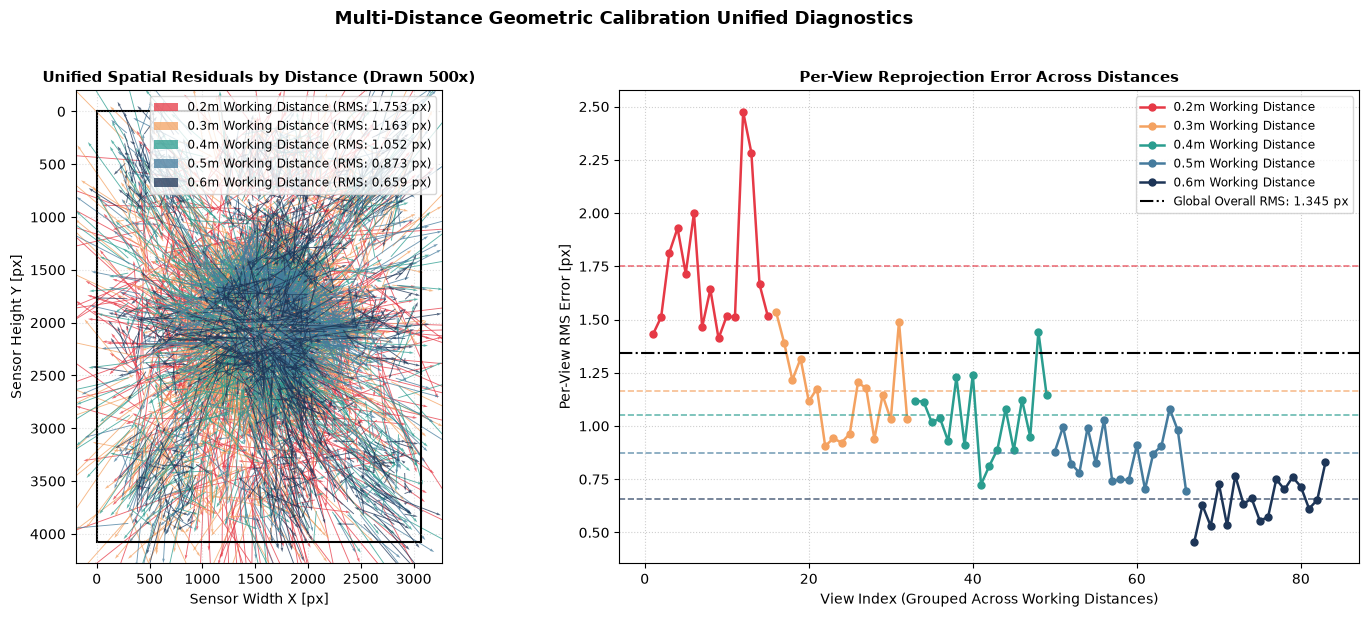

In [7]:
# 4. Unified Color-Coded Residual Plot Function & Execution
def plot_unified_multi_distance_residuals(distance_results, distance_colors, distance_labels, img_shape):
    """
    Plots a 2-panel unified residual diagnostic plot where each working distance
    is assigned a distinct, consistent color.
    Panel 1: Spatial reprojection residual vector map (drawn 500x), color-coded by distance.
    Panel 2: Per-view RMS reprojection error points & lines, color-coded by distance.
    """
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
    
    view_offset = 0
    
    for d_key in ["0_2m", "0_3m", "0_4m", "0_5m", "0_6m"]:
        if d_key not in distance_results:
            continue
            
        payload = distance_results[d_key]
        color = distance_colors[d_key]
        label = distance_labels[d_key]
        
        all_obj = payload["all_obj_points"]
        all_img = payload["all_img_points"]
        rvecs = payload["rvecs"]
        tvecs = payload["tvecs"]
        K = utils.reconstruct_k_matrix(payload)
        dist = utils.reconstruct_dist_vector(payload)
        per_view = payload["per_view_rms_errors"]
        
        # Spatial residual vectors
        res_list, pos_list = [], []
        for i in range(len(all_obj)):
            proj, _ = cv2.projectPoints(all_obj[i], rvecs[i], tvecs[i], K, dist)
            res_list.append(proj.reshape(-1, 2) - all_img[i].reshape(-1, 2))
            pos_list.append(all_img[i].reshape(-1, 2))
            
        res_arr = np.vstack(res_list)
        pos_arr = np.vstack(pos_list)
        
        # Panel 1: Quiver plot overlay for current working distance
        ax1.quiver(
            pos_arr[:, 0], pos_arr[:, 1], res_arr[:, 0], res_arr[:, 1],
            color=color, angles="xy", scale_units="xy", scale=0.002, width=0.0025,
            alpha=0.75, label=f"{label} (RMS: {payload['rms_reprojection_error'][0]:.3f} px)"
        )
        
        # Panel 2: Per-view RMS error points & line
        n_views = len(per_view)
        x_indices = np.arange(view_offset + 1, view_offset + n_views + 1)
        ax2.plot(x_indices, per_view, 'o-', color=color, lw=1.8, ms=5, label=label)
        ax2.axhline(payload['rms_reprojection_error'][0], color=color, ls='--', lw=1.2, alpha=0.7)
        
        view_offset += n_views

    # Format Panel 1 (Spatial Quiver Plot)
    ax1.add_patch(plt.Rectangle((0, 0), img_shape[0], img_shape[1], fill=False, ec="black", lw=1.5))
    ax1.set_xlim(-200, img_shape[0] + 200)
    ax1.set_ylim(img_shape[1] + 200, -200)  # Invert Y to match image coordinates
    ax1.set_aspect("equal")
    ax1.grid(True, linestyle=":", alpha=0.4)
    ax1.set_title("Unified Spatial Residuals by Distance (Drawn 500x)", fontsize=11, fontweight="bold")
    ax1.set_xlabel("Sensor Width X [px]")
    ax1.set_ylabel("Sensor Height Y [px]")
    ax1.legend(fontsize=8.5, loc="upper right")

    # Format Panel 2 (Per-View RMS Errors)
    if "Combined (All)" in distance_results:
        global_rms = distance_results["Combined (All)"]["rms_reprojection_error"][0]
        ax2.axhline(global_rms, color="black", ls="-.", lw=1.5, label=f"Global Overall RMS: {global_rms:.3f} px")

    ax2.set_xlabel("View Index (Grouped Across Working Distances)")
    ax2.set_ylabel("Per-View RMS Error [px]")
    ax2.set_title("Per-View Reprojection Error Across Distances", fontsize=11, fontweight="bold")
    ax2.grid(True, linestyle=":", alpha=0.6)
    ax2.legend(fontsize=8.5, loc="upper right")

    fig.suptitle("Multi-Distance Geometric Calibration Unified Diagnostics", fontsize=13, fontweight="bold", y=1.02)
    plt.tight_layout()
    return fig

# Render Unified Color-Coded Diagnostic Plot
if img_shape_global:
    fig_unified = plot_unified_multi_distance_residuals(
        distance_results=distance_results,
        distance_colors=DISTANCE_COLORS,
        distance_labels=DISTANCE_LABELS,
        img_shape=img_shape_global
    )
    plt.show()